# Fluids
*A wave on shallow water*

A pond has a raised mound of water in the middle. Under gravity the mound collapses and rings of waves travel out.
The shallow-water equations describe this with the depth `h` and the flow `(hu, hv)`, and they conserve water: the
total of `h` never changes. This notebook steps them on a 2-D grid and prints that total as the check.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/anim.py",
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, on_device, plot_style, show, to_numpy, xp
plot_style()

## The pond's words

Say the vocabulary first. The pond is described by the depth `h` and the two momenta `hu` and `hv`; the step needs the gravity `g` and `lam`, the time step over the cell size. Declare them once as a `KernelKind`; the step below is written in these names.

In [3]:
from hawk import Param, Scalar
from hawk.ext import DATA_ONLY, KernelKind


class Water(KernelKind, slug="water"):
    h: Scalar               # depth of the water
    hu: Scalar              # momentum along x
    hv: Scalar              # momentum along y
    lam: Param              # time step over cell size
    g: Param                # gravity
    guard = DATA_ONLY

Water

__main__.Water

## The step

One finite-volume step with a Rusanov flux (also called local Lax-Friedrichs). Across each of a cell's four faces the
flux is the mean of the two cells' fluxes, minus `a` times the jump between them, where `a` is the faster signal speed
of the two, `|flow| + sqrt(g h)`. The flux of the depth is the flow; the fluxes of the flow carry the momentum and the
pressure `g h^2 / 2`. The cell then loses what leaves through its faces. `Grid["row", "col":width]` sizes `row` at run time (`row=N`) and fixes `col`; the last axis declared, `col`, is the fastest (consecutive lanes, so coalesced on a GPU and SIMD on a CPU). The domain wraps around, so the first and last
rows and columns are neighbours; the `if`/`else` picks the wrapped index. The kernel writes three outputs, one per field.

The scheme is first order and diffusive: it smears the waves, and it is the simple, robust choice. Production codes use
the same flux with a higher-order reconstruction. Units: `g = 1`, a cell is 1 wide, still water is 1 deep, and the
step `lam = dt / dx` is 0.35. The scheme is stable while `lam * (a_x + a_y) <= 1`; the run checks the stricter
`lam * (max(|u|, |v|) + sqrt(g h)) < 0.5` at every step.

The helpers are plain functions the kernel calls; the kernel itself assumes the grid has as many rows as columns (the row
wrap uses `width`).

In [4]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Grid, Mutable, Param, Scalar


def push(h, p, g):
    """Momentum flux along its own direction: p^2 / h plus the pressure g h^2 / 2."""
    return p * p / h + 0.5 * g * h * h


def speed(h, p, g):
    """The fastest signal along that direction: the flow plus the wave speed sqrt(g h)."""
    return m.abs(p / h) + m.sqrt(g * h)


def rusanov(f_left, f_right, u_left, u_right, a):
    """The flux across a face: the mean of the two fluxes, minus a times the jump."""
    return 0.5 * (f_left + f_right) - 0.5 * a * (u_right - u_left)


def swe_kernel(width):
    @Water
    def swe_step(lane: Grid["row", "col":width], h, hu, hv, lam, g,
                 h_new: Mutable[Scalar], hu_new: Mutable[Scalar], hv_new: Mutable[Scalar]):
        i, j = lane.row, lane.col
        if i == 0:
            n = i + (width - 1)
        else:
            n = i - 1
        if i == width - 1:
            s = i - (width - 1)
        else:
            s = i + 1
        if j == 0:
            w = j + (width - 1)
        else:
            w = j - 1
        if j == width - 1:
            e = j - (width - 1)
        else:
            e = j + 1
        he, hue, hve = h.at(row=i, col=e), hu.at(row=i, col=e), hv.at(row=i, col=e)
        hw, huw, hvw = h.at(row=i, col=w), hu.at(row=i, col=w), hv.at(row=i, col=w)
        hn, hun, hvn = h.at(row=n, col=j), hu.at(row=n, col=j), hv.at(row=n, col=j)
        hs, hus, hvs = h.at(row=s, col=j), hu.at(row=s, col=j), hv.at(row=s, col=j)
        # east and west faces carry the x flow, south and north the y flow
        a_e = m.max(speed(h, hu, g), speed(he, hue, g))
        a_w = m.max(speed(hw, huw, g), speed(h, hu, g))
        a_s = m.max(speed(h, hv, g), speed(hs, hvs, g))
        a_n = m.max(speed(hn, hvn, g), speed(h, hv, g))
        h_new = h - lam * (rusanov(hu, hue, h, he, a_e) - rusanov(huw, hu, hw, h, a_w)
                           + rusanov(hv, hvs, h, hs, a_s) - rusanov(hvn, hv, hn, h, a_n))
        hu_new = hu - lam * (rusanov(push(h, hu, g), push(he, hue, g), hu, hue, a_e)
                             - rusanov(push(hw, huw, g), push(h, hu, g), huw, hu, a_w)
                             + rusanov(hu * hv / h, hus * hvs / hs, hu, hus, a_s)
                             - rusanov(hun * hvn / hn, hu * hv / h, hun, hu, a_n))
        hv_new = hv - lam * (rusanov(hu * hv / h, hue * hve / he, hv, hve, a_e)
                             - rusanov(huw * hvw / hw, hu * hv / h, hvw, hv, a_w)
                             + rusanov(push(h, hv, g), push(hs, hvs, g), hv, hvs, a_s)
                             - rusanov(push(hn, hvn, g), push(h, hv, g), hvn, hv, a_n))
    return eagle.deploy(swe_step)


def mound(width):
    """Still water of depth 1 with a smooth raised mound in the middle."""
    y, x = np.mgrid[0:width, 0:width]
    h = 1.0 + 0.4 * np.exp(-((x - width / 2) ** 2 + (y - width / 2) ** 2) / (width / 6) ** 2)
    return h, np.zeros_like(h), np.zeros_like(h)


N, LAM, G = 64, 0.35, 1.0
step = swe_kernel(N)
state = mound(N)
out = step.run(h=state[0], hu=state[1], hv=state[2], lam=LAM, g=G, row=N)
sorted(out)

['h_new', 'hu_new', 'hv_new']

## Check one step against NumPy

The same step with `np.roll` for the neighbours. The three outputs must agree to rounding.

In [5]:
def numpy_step(h, hu, hv, lam, g):
    u = np.array([h, hu, hv])
    out = u.copy()
    for axis in (2, 1):                                  # columns carry hu, rows carry hv
        c, o = 3 - axis, axis                            # the flow along this axis, and the other one

        def flux(q):
            f = np.empty_like(q)
            f[0] = q[c]
            f[c] = q[c] ** 2 / q[0] + 0.5 * g * q[0] ** 2
            f[o] = q[c] * q[o] / q[0]
            return f

        right = np.roll(u, -1, axis)
        a = np.abs(u[c] / u[0]) + np.sqrt(g * u[0])
        a = np.maximum(a, np.roll(a, -1, axis - 1))
        face = 0.5 * (flux(u) + flux(right)) - 0.5 * a * (right - u)
        out -= lam * (face - np.roll(face, 1, axis))
    return out


TOL = 1e-12
want = numpy_step(*state, LAM, G)
err = max(np.abs(out[k] - w).max() for k, w in zip(("h_new", "hu_new", "hv_new"), want))
assert err < TOL, err
print(f"one step: largest difference from NumPy {err:.1e} < {TOL:g}")

one step: largest difference from NumPy 2.2e-16 < 1e-12


## Run it and check the physics

Feed the three outputs back in. Two sets of arrays take turns, and `step.bind` ties each direction to its arrays once:
`forward` reads set `A` and writes set `B`, `backward` reads `B` and writes `A`, and a step is one `.launch()`,
alternating the two. On a
GPU the fields stay on the device and copying a frame home is the only wait per frame (`xp` is CuPy there, NumPy
otherwise).

Once per frame the run checks the stability number. At the end three things are compared with what the equations say:

- the total depth: water is neither made nor lost;
- the symmetry: a round mound on a square grid must stay mirror-symmetric;
- the energy `sum(0.5 (hu^2 + hv^2) / h + 0.5 g h^2)`: it must not grow. The scheme loses a little of it to its own
  numerical diffusion, and that loss is printed.

In [6]:
steps_per_frame, n_frames = 3, 40
A = [xp.array(a) for a in state]
B = [xp.empty_like(a) for a in A]
forward = step.bind(h=A[0], hu=A[1], hv=A[2], lam=LAM, g=G, row=N, h_new=B[0], hu_new=B[1], hv_new=B[2])   # A -> B
backward = step.bind(h=B[0], hu=B[1], hv=B[2], lam=LAM, g=G, row=N, h_new=A[0], hu_new=A[1], hv_new=A[2])  # B -> A
launches, sets, which = (forward, backward), (A, B), 0


def energy(h, hu, hv):
    return float((0.5 * (hu ** 2 + hv ** 2) / h + 0.5 * G * h ** 2).sum())


frames, volume, total_energy = [state[0]], [state[0].sum()], [energy(*A)]
worst_cfl = 0.0
for _ in range(n_frames - 1):
    for _ in range(steps_per_frame):
        launches[which].launch()
        which = 1 - which
    cur = sets[which]
    h, hu, hv = cur
    cfl = LAM * float((xp.maximum(abs(hu / h), abs(hv / h)) + xp.sqrt(G * h)).max())
    assert cfl < 0.5, cfl
    worst_cfl = max(worst_cfl, cfl)
    frames.append(to_numpy(cur[0]).copy())
    volume.append(float(cur[0].sum()))
    total_energy.append(energy(*cur))

volume, total_energy = np.array(volume), np.array(total_energy)
TOL_MASS = 1e-12
drift = np.abs(volume / volume[0] - 1.0).max()
assert drift < TOL_MASS, drift
print(f"water: total depth {volume[0]:.4f} at the start, {volume[-1]:.4f} at the end; "
      f"largest relative change {drift:.1e} < {TOL_MASS:g}")

final = frames[-1]
TOL_SYM = 1e-12
assert np.abs(final - final.T).max() < TOL_SYM
print(f"symmetry: largest difference between the depth and its mirror image {np.abs(final - final.T).max():.1e} < {TOL_SYM:g}")

assert np.all(np.diff(total_energy) <= 0.0), "the energy must not grow"
print(f"energy: {total_energy[0]:.2f} -> {total_energy[-1]:.2f}, a drop of "
      f"{100 * (1 - total_energy[-1] / total_energy[0]):.2f} % (the scheme's numerical diffusion); "
      f"largest stability number {worst_cfl:.2f} < 0.5")

water: total depth 4238.9709 at the start, 4238.9709 at the end; largest relative change 2.2e-16 < 1e-12
symmetry: largest difference between the depth and its mirror image 4.4e-16 < 1e-12
energy: 2205.27 -> 2200.68, a drop of 0.21 % (the scheme's numerical diffusion); largest stability number 0.42 < 0.5


The depth at the start and part-way through, and the total along the way. The colour scale starts at the mound's full height, so the first panel is not clipped:


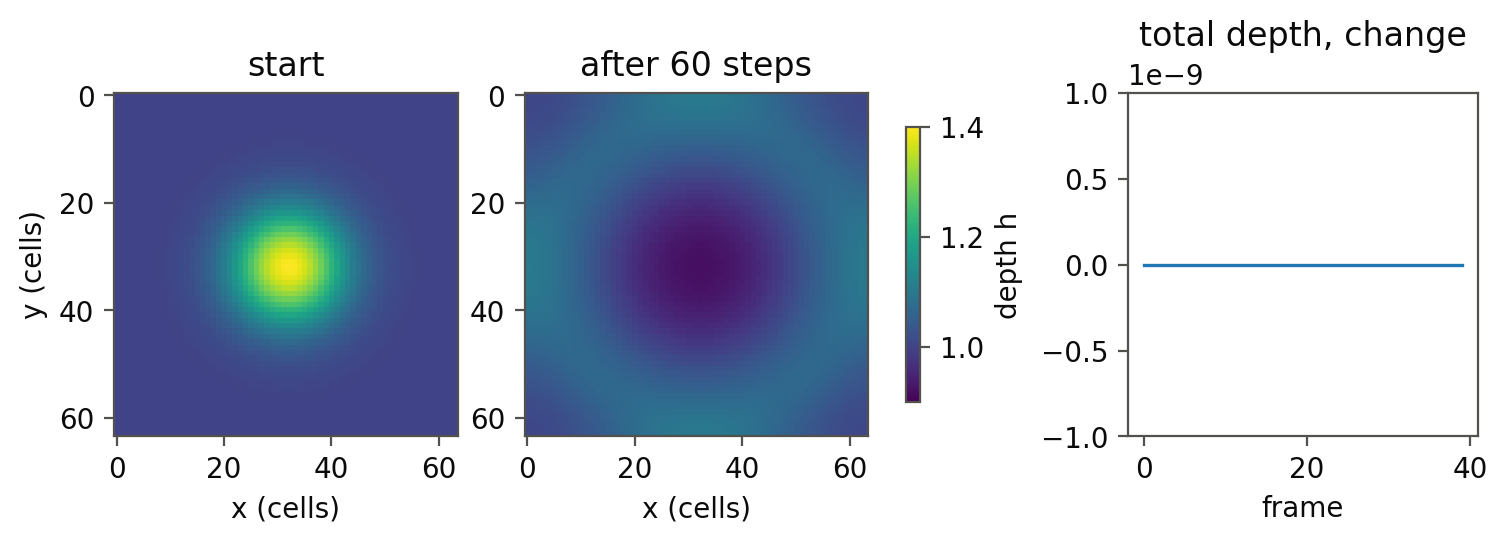
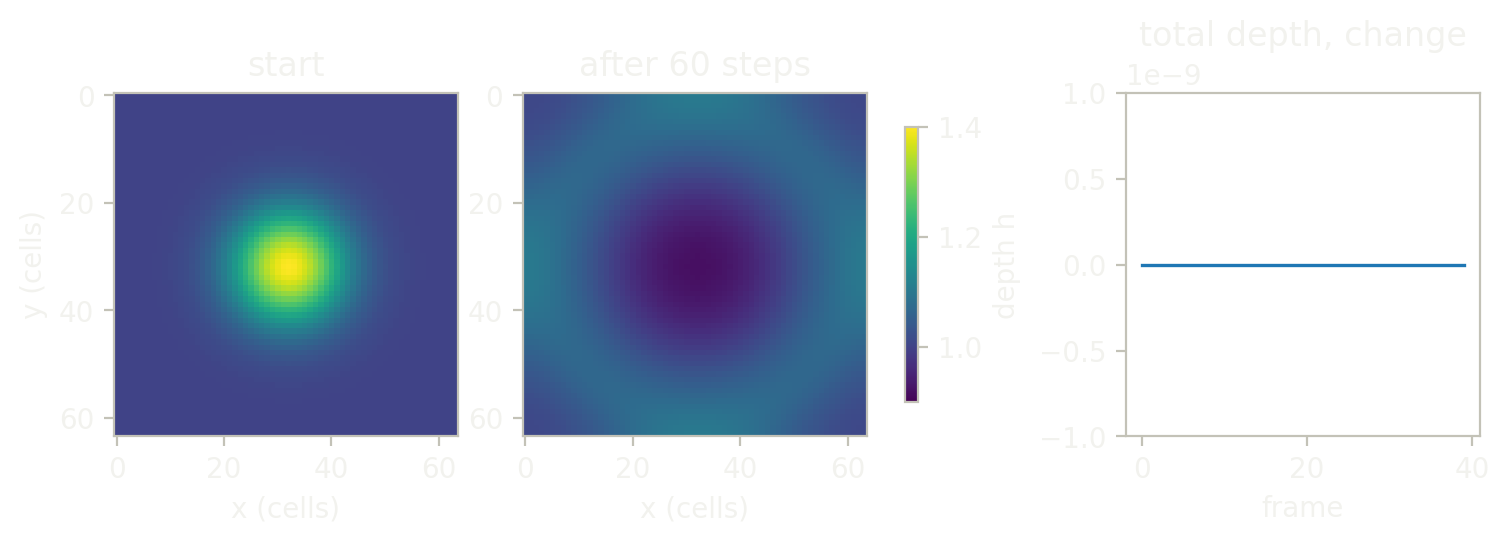

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.6), constrained_layout=True)
for ax, f, title in zip(axes[:2], (frames[0], frames[n_frames // 2]), ("start", f"after {steps_per_frame * (n_frames // 2)} steps")):
    im = ax.imshow(f, vmin=0.9, vmax=1.4, cmap="viridis")
    ax.set_title(title); ax.set_xlabel("x (cells)")
axes[0].set_ylabel("y (cells)")
fig.colorbar(im, ax=axes[:2], shrink=0.8, label="depth h")
axes[2].plot(volume / volume[0] - 1.0, lw=1.2)
axes[2].set_ylim(-1e-9, 1e-9)
axes[2].set_xlabel("frame"); axes[2].set_title("total depth, change")
show()

## A bigger pond, when a GPU is there

The same kernel with a wider grid. Where the data lies decides where the kernel runs: NumPy arrays on the host, CuPy
arrays on the GPU. So the fields are handed over as device arrays and come back as device arrays; the check against NumPy
copies them home first. To choose a side yourself, use `step.host.run(...)` or `step.device.run(...)`: the device plan takes NumPy
arrays, uploads them, runs on the GPU and brings the result home.

In [8]:
if gpu_available():
    big = 1024
    big_step = swe_kernel(big)
    sb = mound(big)
    got = big_step.run(h=xp.asarray(sb[0]), hu=xp.asarray(sb[1]), hv=xp.asarray(sb[2]), lam=LAM, g=G, row=big)
    assert on_device(got["h_new"]), "the result is a device array: the kernel ran on the GPU"
    ref = numpy_step(*sb, LAM, G)
    err = max(np.abs(to_numpy(got[k]) - w).max() for k, w in zip(("h_new", "hu_new", "hv_new"), ref))
    assert err < TOL, err
    print(f"{big} x {big} on the GPU (result is a device array): largest difference from NumPy {err:.1e}")
else:
    print("no GPU here; the grid stays at", N, "x", N)

1024 x 1024 on the GPU (result is a device array): largest difference from NumPy 2.2e-16


## The animation

The last cell writes the depth frames as a looping GIF, one for a light page and one for a dark page; the page shows the file written when the notebook last ran.

In [9]:
import matplotlib.pyplot as plt
from anim import frame_of, write_anim
from themed_figure import DARK, LIGHT


def render(theme, field, label):
    pal = LIGHT if theme == "light" else DARK
    fig = plt.figure(figsize=(2.6, 2.8), dpi=80, facecolor=pal["bg"])
    ax = fig.add_axes([0.04, 0.12, 0.92, 0.84])
    ax.axis("off")
    ax.imshow(field, vmin=0.9, vmax=1.4, cmap="viridis", interpolation="nearest")
    fig.text(0.5, 0.04, label, ha="center", fontsize=9, color=pal["sub"])
    return frame_of(fig, pal["bg"])


for theme in ("light", "dark"):
    movie = [render(theme, f, f"step {k * steps_per_frame}") for k, f in enumerate(frames)]
    for name, size in write_anim(movie, "shallow_water_" + theme).items():
        print(name, f"{size / 1e3:.0f} kB")

shallow_water_light.gif 859 kB


shallow_water_dark.gif 849 kB


```{image} ../../_static/anim/shallow_water_light.gif
:class: only-light narrow
:alt: A mound of water collapsing into rings of waves that cross a periodic pond
```
```{image} ../../_static/anim/shallow_water_dark.gif
:class: only-dark narrow
:alt: A mound of water collapsing into rings of waves that cross a periodic pond
```

## What just happened

- One kernel with three outputs advanced depth and flow together; `.at` read the four neighbours, with the
  `if`/`else` choosing the wrapped index, and a Rusanov flux crossed each face.
- One step matched NumPy to rounding.
- The total depth stayed fixed, the mound stayed mirror-symmetric, and the energy fell slightly, as a first-order
  scheme's diffusion makes it.

## Next

[Orbits](06_orbits) shows a state vocabulary for a different domain.